# Exploratory Data Analysis (EDA)
In this notebook, we analyze the engineered data to answer key questions:
1. **Is the bunching class balanced or imbalanced?**
2. How is passenger demand distributed across hours and routes?
3. How do scheduled headways compare to actual headways?

Data is read directly from `cleaned_data/`.


## 1. Load Data from `cleaned_data/`


In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Auto-navigate to project root if running inside subfolder
if os.path.basename(os.getcwd()) in ["data preprocessing", "EDA"]:
    os.chdir("..")

df_demand = pd.read_csv("cleaned_data/hourly_demand_operations.csv", low_memory=False)
df_trips = pd.read_csv("cleaned_data/trip_operations.csv", low_memory=False)

print("Loaded cleaned_data successfully.")


Loaded cleaned_data successfully.


## 2. Class Balance Analysis: Is the bunching class balanced or not?
Here we check the distribution of the target variable `bunching_label` in trips data.


Bunching Label Counts:
bunching_label
0    310482
1      8893
Name: count, dtype: int64

Bunching Label Percentages:
bunching_label
0    97.215499
1     2.784501
Name: proportion, dtype: float64


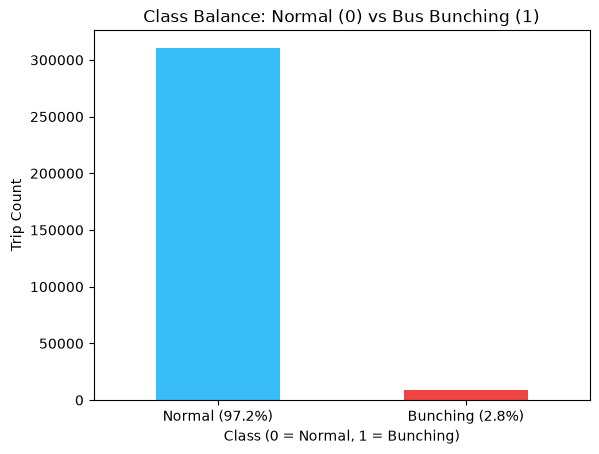

In [2]:
# Value counts and percentages for bunching_label
print("Bunching Label Counts:")
print(df_trips["bunching_label"].value_counts())

print("\nBunching Label Percentages:")
print(df_trips["bunching_label"].value_counts(normalize=True) * 100)

# Simple Bar Plot for Class Balance
df_trips["bunching_label"].value_counts().plot(kind='bar', color=['#38bdf8', '#ef4444'])
plt.title("Class Balance: Normal (0) vs Bus Bunching (1)")
plt.xlabel("Class (0 = Normal, 1 = Bunching)")
plt.ylabel("Trip Count")
plt.xticks(ticks=[0, 1], labels=['Normal (97.2%)', 'Bunching (2.8%)'], rotation=0)
plt.show()


**Finding on Class Balance**:
The class is **severely imbalanced**:
- **Class 0 (Normal)**: 310,482 trips (**97.22%**)
- **Class 1 (Bunching)**: 8,893 trips (**2.78%**)

Because bunching is a rare event (only 2.78%), classification models must use `class_weight='balanced'`, and we must evaluate models using **Recall** and **ROC-AUC** rather than simple accuracy!


## 3. Passenger Demand Distribution & Peak Hours


count    74470.000000
mean       139.553229
std         88.715711
min         12.000000
25%         74.000000
50%        120.000000
75%        180.000000
max        638.000000
Name: passenger_demand, dtype: float64


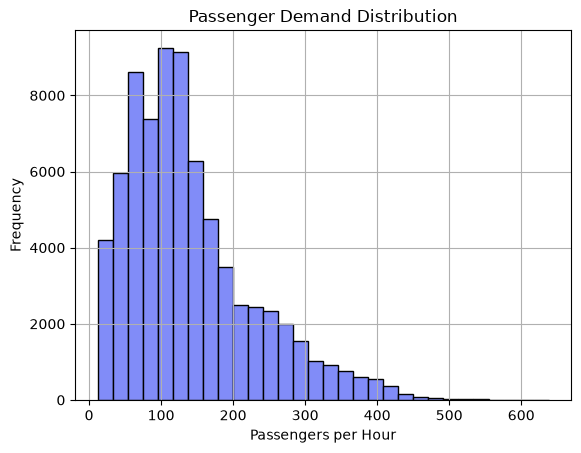

In [3]:
# Statistical summary of passenger demand
print(df_demand["passenger_demand"].describe())

# Histogram of passenger demand
df_demand["passenger_demand"].hist(bins=30, color='#818cf8', edgecolor='black')
plt.title("Passenger Demand Distribution")
plt.xlabel("Passengers per Hour")
plt.ylabel("Frequency")
plt.show()


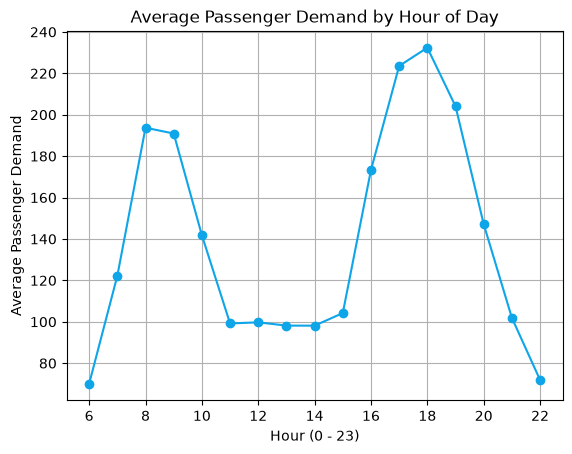

In [4]:
# Average demand by hour of the day (finding peak hours)
hourly_demand = df_demand.groupby("hour_int")["passenger_demand"].mean()
hourly_demand.plot(kind='line', marker='o', color='#0ea5e9')
plt.title("Average Passenger Demand by Hour of Day")
plt.xlabel("Hour (0 - 23)")
plt.ylabel("Average Passenger Demand")
plt.grid(True)
plt.show()


## 4. Headway Relationship (60% Bunching Rule)


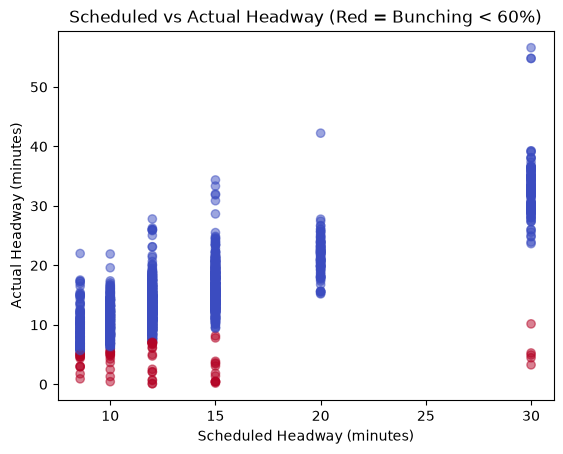

In [5]:
# Sample trips for simple scatter plot
sample = df_trips.sample(n=2000, random_state=42)

plt.scatter(sample["scheduled_headway_min"], sample["actual_headway_min"], 
            c=sample["bunching_label"], cmap='coolwarm', alpha=0.5)
plt.title("Scheduled vs Actual Headway (Red = Bunching < 60%)")
plt.xlabel("Scheduled Headway (minutes)")
plt.ylabel("Actual Headway (minutes)")
plt.show()


## 5. Capacity Shortage Analysis


In [6]:
# Shortage statistics
print("Capacity shortage summary:")
print(df_demand["capacity_shortage"].describe())

# Top routes with capacity shortage
print("\nTop 5 corridors with highest shortage:")
print(df_demand.groupby("route_id")["capacity_shortage"].sum().sort_values(ascending=False).head())


Capacity shortage summary:
count    74470.000000
mean         3.902739
std         18.144489
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max        366.000000
Name: capacity_shortage, dtype: float64

Top 5 corridors with highest shortage:
route_id
L01    56556
L04    30495
R03    30179
L03    27872
L02    25252
Name: capacity_shortage, dtype: int64
